# MLD sample run

This notebook demonstrates Model Live Diagnostics (MLD) on six years of monthly ACCESS-OM2 1° ocean output (1958–1963) in `mld_sample_om2/`. Run it from this folder, so the relative path to the data works.

Comparing against reference models needs the ACCESS-NRI catalog on NCI's Gadi supercomputer. Here the reference card will say there are no reference models, and overlay plots aren't available. Everything else works off Gadi.

## 1. Interactive session

Run the cell below, then in the start card:

1. Set the model type to **OM2**.
2. Enter `mld_sample_om2` as the model data path.
3. Start the session.

Once the catalog is built, choose a dataset, load it, and try line plots, heatmaps, animations and the analysis recipes.

To see live updates, move one year of files out of `mld_sample_om2/output000/ocean/`, start a session, move them back, then refresh.


----------------------- Live diagnostics session started -----------------------

Model type: OM2
Model data path: mld_sample_om2

Started dask client: http://127.0.0.1:60083/status

--------------------------------------------------------------------------------


BokehModel(combine_events=True, render_bundle={'docs_json': {'d2d65b73-b957-4ff9-bd1d-3290e2570c77': {'version…

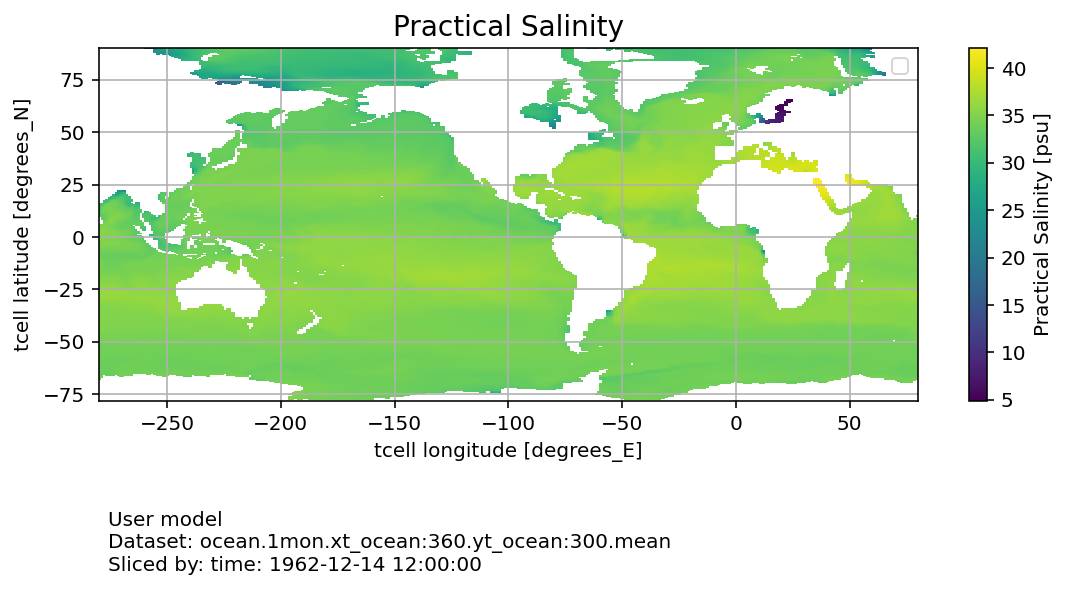

In [7]:
import os
import warnings

import med_diagnostics

# Hide library warnings to keep the demo readable, including in Dask's worker processes
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"

session = med_diagnostics.session.CreateModelDiagnosticsSession()

## 2. Scripting with the API

The same diagnostics can be run without the interface, using `med_diagnostics.api`.

Build a catalog of the run and list its datasets:

In [8]:
from IPython.display import display

from med_diagnostics import api

cat = api.build_catalog("mld_sample_om2", "OM2")
api.list_datasets(cat)

Building user data catalog for model type: OM2 and model_path: mld_sample_om2
This can take a few minutes.
Datastore found in /Users/theoe/.med_diagnostics/catalogs/mld_sample_om2_8d431cda, verifying datastore integrity...
Sucessfully built esm-datastore!
Datastore integrity verified!


['ocean.1mon.scalar_axis:1.mean', 'ocean.1mon.xt_ocean:360.yt_ocean:300.mean']

Load the gridded monthly fields and the global averages:

In [9]:
ds = api.load_dataset(cat, "ocean.1mon.xt_ocean:360.yt_ocean:300.mean")
scalars = api.load_dataset(cat, "ocean.1mon.scalar_axis:1.mean")
ds

<xarray.Dataset> Size: 93MB
Dimensions:   (time: 72, yt_ocean: 300, xt_ocean: 360)
Coordinates:
  * time      (time) object 576B 1958-01-14 12:00:00 ... 1963-12-14 12:00:00
  * yt_ocean  (yt_ocean) float64 2kB -77.88 -77.63 -77.38 ... 88.87 89.32 89.77
  * xt_ocean  (xt_ocean) float64 3kB -279.5 -278.5 -277.5 ... 77.5 78.5 79.5
Data variables:
    sst       (time, yt_ocean, xt_ocean) float32 31MB dask.array<chunksize=(1, 300, 360), meta=np.ndarray>
    sss       (time, yt_ocean, xt_ocean) float32 31MB dask.array<chunksize=(1, 300, 360), meta=np.ndarray>
    mld       (time, yt_ocean, xt_ocean) float32 31MB dask.array<chunksize=(1, 300, 360), meta=np.ndarray>
Attributes: (12/16)
    filename:                                 ocean_month.nc
    title:                                    ACCESS-OM2-BGC
    grid_type:                                mosaic
    grid_tile:                                1
    intake_esm_vars:                          ('mld', 'sss', 'sst', 'time', '...
    intake_esm_attrs:file_id:                 ocean.1mon.xt_ocean:360.yt_ocea...
    ...                                       ...
    intake_esm_attrs:variable_cell_methods:   time: mean,time: mean,time: mea...
    intake_esm_attrs:variable_units:          m,psu,K,days since 0001-01-01,d...
    intake_esm_attrs:realm:                   ocean
    intake_esm_attrs:temporal_label:          mean
    intake_esm_attrs:_data_format_:           netcdf
    intake_esm_dataset_key:                   ocean.1mon.xt_ocean:360.yt_ocea...

### Plots

A line plot of global mean temperature:

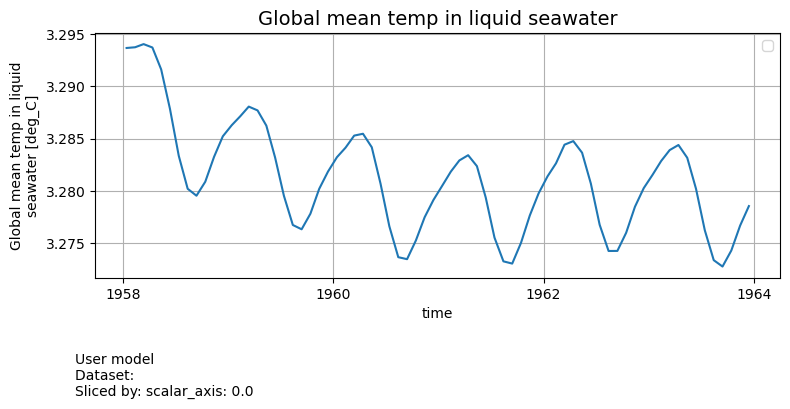

In [10]:
fig = api.plot_data(scalars, "temp_global_ave", x_axis="time")

A map of sea surface temperature for July 1958:

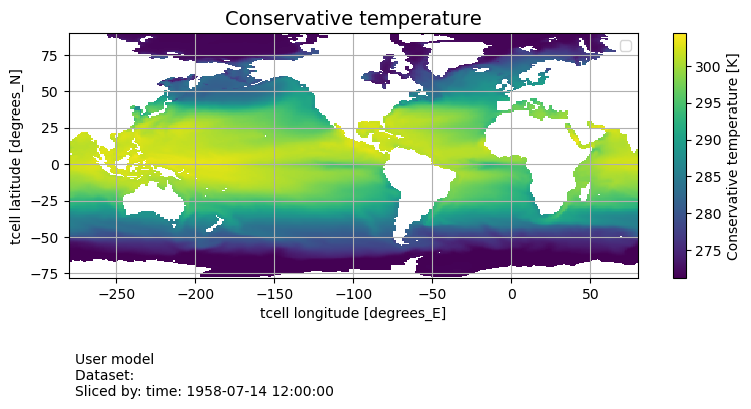

In [11]:
fig = api.plot_data(
    ds, "sst", x_axis="xt_ocean", y_axis="yt_ocean", slices={"time": ds.time.values[6]}
)

An animation of sea surface temperature over time:

In [12]:
display(
    api.plot_data(ds, "sst", x_axis="xt_ocean", y_axis="yt_ocean", animate_over="time")
)

BokehModel(combine_events=True, render_bundle={'docs_json': {'d9efa407-9e7f-4a04-aebb-151c0a0daab3': {'version…

### Analysis recipes

List the available recipes, and the arguments one takes:

In [13]:
list(api.list_recipes())

['OM3 timeseries suite (OM3 variable names)',
 'OM3 timeseries suite (custom variable mapping)',
 'Timeseries of a variable over a chosen region (Area-weighted mean).',
 'Niño 3.4 index for sea surface temperature']

In [14]:
api.recipe_options("Niño 3.4 index for sea surface temperature", ds)

[{'name': 'var',
  'label': 'Select Variable',
  'kind': 'data variable',
  'required': False,
  'default': 'tos',
  'choices': ['sst', 'sss', 'mld'],
  'units': None,
  'description': 'Sea surface temperature variable in this dataset (default tos)'},
 {'name': 'x_dim',
  'label': 'Select Longitude Dim',
  'kind': 'dimension',
  'required': False,
  'default': 'xt_ocean',
  'choices': ['xt_ocean', 'yt_ocean', 'time'],
  'units': None,
  'description': 'Longitude dimension'},
 {'name': 'y_dim',
  'label': 'Select Latitude Dim',
  'kind': 'dimension',
  'required': False,
  'default': 'yt_ocean',
  'choices': ['xt_ocean', 'yt_ocean', 'time'],
  'units': None,
  'description': 'Latitude dimension'}]

Run a regional mean timeseries and the Niño 3.4 index:

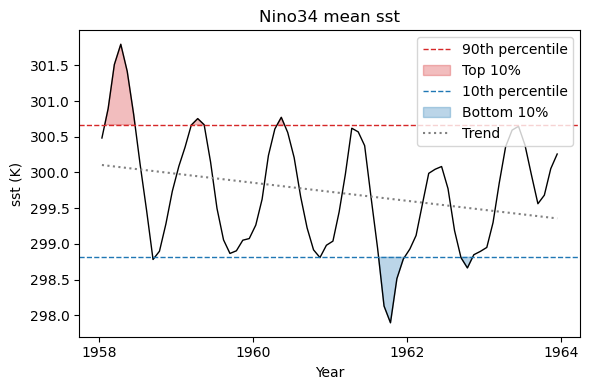

In [15]:
figs = api.run_recipe(
    ds,
    "Timeseries of a variable over a chosen region (Area-weighted mean).",
    variable="sst",
    region="nino34",
)

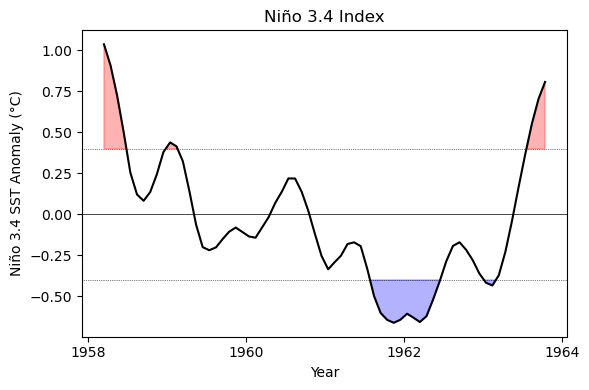

In [16]:
figs = api.run_recipe(ds, "Niño 3.4 index for sea surface temperature", var="sst")